In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.optimize import curve_fit

In [4]:
O5V_star = np.loadtxt('Spe\\O5V.dat')
O7III_star = np.loadtxt('Spe\\O7-B1III.dat')
O7V_star = np.loadtxt('Spe\\O7--B0V.dat')
B3V_star = np.loadtxt('Spe\\B3--4V.dat')
B5III_star = np.loadtxt('Spe\\B5III.dat')
B6V_star = np.loadtxt('Spe\\B6V.dat')
A_star = np.loadtxt('Spe\\A1--3V.dat')
A3III_star = np.loadtxt('Spe\\A3III.dat')
A5V_star = np.loadtxt('Spe\\A5--7V.dat')
A6V_star = np.loadtxt('Spe\\A6--F0~1.dat')
A7IV_star = np.loadtxt('Spe\\A7IV.dat')
A8V_star = np.loadtxt('Spe\\A8V.dat')
A9V_star = np.loadtxt('Spe\\A9--F0V.dat')
F3IV_star = np.loadtxt('Spe\\F3IV.dat')
F4III_star = np.loadtxt('Spe\\F4-7III.dat')
F6V_star = np.loadtxt('Spe\\F6--7V.dat')
F8V_star = np.loadtxt('Spe\\F8--9V.dat')
G0III_star = np.loadtxt('Spe\\GO--4III.dat')
G1V_star = np.loadtxt('Spe\\G1--2V.dat')
G2IV_star = np.loadtxt('Spe\\G2IV.dat')
G5III_star = np.loadtxt('Spe\\G5--6III.dat')
G5IV_star = np.loadtxt('Spe\\G5IV.dat')
G6V_star = np.loadtxt('Spe\\G6--8V.dat')
G8IV_star = np.loadtxt('Spe\\G8IV.dat')
G8V_star = np.loadtxt('Spe\\G8--K0~1.dat')
G9V_star = np.loadtxt('Spe\\G9--K0V.dat')
K2III_star = np.loadtxt('Spe\\K2III.dat')
K4III_star = np.loadtxt('Spe\\K4III.dat')
K4V_star = np.loadtxt('Spe\\K4V.dat')
K5V_star = np.loadtxt('Spe\\K5V.dat')
M2V_star = np.loadtxt('Spe\\M2V.dat')
M4V_star = np.loadtxt('Spe\\M4V.dat')
U = np.loadtxt('Spe\\U1.dat')
B = np.loadtxt('Spe\\B1.dat')
V = np.loadtxt('Spe\\V1.dat')
R = np.loadtxt('Spe\\R1.dat')

In [5]:
def get_variable_name(variable):
    for name in globals():
        if id(globals()[name]) == id(variable):
            return name
    for name in locals():
        if id(locals()[name]) == id(variable):
            return name
    return None

In [6]:
def fl_rel(filter1, filter2, star):
    filter = ((filter1[:,0] >= star[0,0]))
    filter1_star = filter1[filter]
    filter = ((star[:,0] <= filter1_star[-1,0]) & (star[:,0] >= filter1_star[0,0]))
    star_filter1 = star[filter]
    if len(filter1_star[:, 0]) >= len(star_filter1[:,0]):
        star_filter1_flux = np.interp(filter1_star[:, 0], star_filter1[:, 0], star_filter1[:, 1])
        star_filter1_wl = filter1_star[:, 0].copy()
    else:
        star_filter1_flux = np.interp(star_filter1[:, 0], filter1_star[:, 0], star_filter1[:, 1])
        star_filter1_wl = star_filter1[:, 0].copy()
    
    filter = ((filter2[:,0] >= star[0,0]))
    filter2_star = filter2[filter]
    filter = ((star[:,0] <= filter2_star[-1,0]) & (star[:,0] >= filter2_star[0,0]))
    star_filter2 = star[filter]
    if len(filter2_star[:, 0]) >= len(star_filter2[:,0]):
        star_filter2_flux = np.interp(filter2_star[:, 0], star_filter2[:, 0], star_filter2[:, 1])
        star_filter2_wl = filter2_star[:, 0].copy()
    else:
        star_filter2_flux = np.interp(star_filter2[:, 0], filter2_star[:, 0], star_filter2[:, 1])
        star_filter2_wl = star_filter2[:, 0].copy()
    
    Flux_filter1_star = simpson(star_filter1_flux*filter1_star[:, 1], star_filter1_wl)
    Flux_filter2_star = simpson(star_filter2_flux*filter2_star[:, 1], star_filter2_wl)
    
    return(Flux_filter1_star/Flux_filter2_star)

In [7]:
def color(flux_rel_star, flux_rel_star_A):
    return -2.5*(np.log10(flux_rel_star) - np.log10(flux_rel_star_A))

In [8]:
def plot(filter1, filter2, star, filter1_name, filter2_name, star_name):
    fig1 = plt.figure()
    plt.plot(star[:, 0], star[:, 1], color='green', label=star_name)
    plt.legend(loc='best')
    #fig2 = plt.figure()
    #plt.plot(filter1[:, 0], filter1[:, 1], color='blue', label=filter1_name)
    #plt.plot(filter2[:, 0], filter2[:, 1], color='red', label=filter2_name)
    plt.legend(loc='best')

In [9]:
UV_rel_O5V_star = fl_rel(U, V, O5V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_O5V_star_color = color(UV_rel_O5V_star, UV_rel_A_star)
print('U-V O5V', UV_O5V_star_color)
UV_rel_F3IV_star = fl_rel(U, V, F3IV_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_F3IV_star_color = color(UV_rel_F3IV_star, UV_rel_A_star)
print('U-V F3IV', UV_F3IV_star_color)
UV_rel_A7IV_star = fl_rel(U, V, A7IV_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_A7IV_star_color = color(UV_rel_A7IV_star, UV_rel_A_star)
print('U-V A7IV', UV_A7IV_star_color)
UV_rel_B3V_star = fl_rel(U, V, B3V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_B3V_star_color = color(UV_rel_B3V_star, UV_rel_A_star)
print('U-V B3V', UV_B3V_star_color)
UV_rel_F6V_star = fl_rel(U, V, F6V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_F6V_star_color = color(UV_rel_F6V_star, UV_rel_A_star)
print('U-V F6V', UV_F6V_star_color)
UV_rel_F4III_star = fl_rel(U, V, F4III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_F4III_star_color = color(UV_rel_F4III_star, UV_rel_A_star)
print('U-V F4III', UV_F4III_star_color)
UV_rel_O7III_star = fl_rel(U, V, O7III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_O7III_star_color = color(UV_rel_O7III_star, UV_rel_A_star)
print('U-V O7III', UV_O7III_star_color)
UV_rel_O7V_star = fl_rel(U, V, O7V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_O7V_star_color = color(UV_rel_O7V_star, UV_rel_A_star)
print('U-V O7V', UV_O7V_star_color)
UV_rel_B5III_star = fl_rel(U, V, B5III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_B5III_star_color = color(UV_rel_B5III_star, UV_rel_A_star)
print('U-V B5III', UV_B5III_star_color)
UV_rel_B6V_star = fl_rel(U, V, B6V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_B6V_star_color = color(UV_rel_B6V_star, UV_rel_A_star)
print('U-V B6V', UV_B6V_star_color)
UV_rel_A3III_star = fl_rel(U, V, A3III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_A3III_star_color = color(UV_rel_A3III_star, UV_rel_A_star)
print('U-V A3III', UV_A3III_star_color)
UV_rel_A5V_star = fl_rel(U, V, A5V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_A5V_star_color = color(UV_rel_A5V_star, UV_rel_A_star)
print('U-V A5V', UV_A5V_star_color)
UV_rel_A6V_star = fl_rel(U, V, A6V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_A6V_star_color = color(UV_rel_A6V_star, UV_rel_A_star)
print('U-V A6V', UV_A6V_star_color)
UV_rel_A8V_star = fl_rel(U, V, A8V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_A8V_star_color = color(UV_rel_A8V_star, UV_rel_A_star)
print('U-V A8V', UV_A8V_star_color)
UV_rel_A9V_star = fl_rel(U, V, A9V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_A9V_star_color = color(UV_rel_A9V_star, UV_rel_A_star)
print('U-V A9V', UV_A9V_star_color)
UV_rel_G0III_star = fl_rel(U, V, G0III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G0III_star_color = color(UV_rel_G0III_star, UV_rel_A_star)
print('U-V G0III', UV_G0III_star_color)
UV_rel_G1V_star = fl_rel(U, V, G1V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G1V_star_color = color(UV_rel_G1V_star, UV_rel_A_star)
print('U-V G1V', UV_G1V_star_color)
UV_rel_G2IV_star = fl_rel(U, V, G2IV_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G2IV_star_color = color(UV_rel_G2IV_star, UV_rel_A_star)
print('U-V G2IV', UV_G2IV_star_color)
UV_rel_G5III_star = fl_rel(U, V, G5III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G5III_star_color = color(UV_rel_G5III_star, UV_rel_A_star)
print('U-V G5III', UV_G5III_star_color)
UV_rel_G5IV_star = fl_rel(U, V, G5IV_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G5IV_star_color = color(UV_rel_G5IV_star, UV_rel_A_star)
print('U-V G5IV', UV_G5IV_star_color)
UV_rel_G6V_star = fl_rel(U, V, G6V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G6V_star_color = color(UV_rel_G6V_star, UV_rel_A_star)
print('U-V G6V', UV_G6V_star_color)
UV_rel_G8IV_star = fl_rel(U, V, G8IV_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G8IV_star_color = color(UV_rel_G8IV_star, UV_rel_A_star)
print('U-V G8IV', UV_G8IV_star_color)
UV_rel_G8V_star = fl_rel(U, V, G8V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G8V_star_color = color(UV_rel_G8V_star, UV_rel_A_star)
print('U-V G8V', UV_G8V_star_color)
UV_rel_G9V_star = fl_rel(U, V, G9V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_G9V_star_color = color(UV_rel_G9V_star, UV_rel_A_star)
print('U-V G9V', UV_G9V_star_color)
UV_rel_K2III_star = fl_rel(U, V, K2III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_K2III_star_color = color(UV_rel_K2III_star, UV_rel_A_star)
print('U-V K2III', UV_K2III_star_color)
UV_rel_K4III_star = fl_rel(U, V, K4III_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_K4III_star_color = color(UV_rel_K4III_star, UV_rel_A_star)
print('U-V K4III', UV_K4III_star_color)
UV_rel_K4V_star = fl_rel(U, V, K4V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_K4V_star_color = color(UV_rel_K4V_star, UV_rel_A_star)
print('U-V K4V', UV_K4V_star_color)
UV_rel_K5V_star = fl_rel(U, V, K5V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_K5V_star_color = color(UV_rel_K5V_star, UV_rel_A_star)
print('U-V K5V', UV_K5V_star_color)
UV_rel_M2V_star = fl_rel(U, V, M2V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_M2V_star_color = color(UV_rel_M2V_star, UV_rel_A_star)
print('U-V M2V', UV_M2V_star_color)
UV_rel_M4V_star = fl_rel(U, V, M4V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_M4V_star_color = color(UV_rel_M4V_star, UV_rel_A_star)
print('U-V M4V', UV_M4V_star_color)
UV_rel_F8V_star = fl_rel(U, V, F8V_star)
UV_rel_A_star = fl_rel(U, V, A_star)
UV_F8V_star_color = color(UV_rel_F8V_star, UV_rel_A_star)
print('U-V F8V', UV_F8V_star_color)

U-V O5V -1.4249991607798729
U-V F3IV 0.259058409028658
U-V A7IV 0.08352651340757751
U-V B3V -0.8833961443011149
U-V F6V 0.3818129695708327
U-V F4III 0.3777980054200799
U-V O7III -1.3297951992239936
U-V O7V -1.3528705476087124
U-V B5III -0.956732230231393
U-V B6V -0.5763474661753334
U-V A3III -0.0575048208340153
U-V A5V 0.05903639370623083
U-V A6V 0.1834913282259517
U-V A8V 0.3660156088261484
U-V A9V 0.21687710006467054
U-V G0III 0.9095964034830495
U-V G1V 0.581869298466974
U-V G2IV 0.6707869263361845
U-V G5III 0.9866401743356679
U-V G5IV 0.9341858238290637
U-V G6V 0.7784017216782537
U-V G8IV 1.0776588499256403
U-V G8V 1.5321100488185693
U-V G9V 1.147150335477727
U-V K2III 2.0301666485953938
U-V K4III 2.6663788257940553
U-V K4V 1.656729216017877
U-V K5V 2.2245390530107287
U-V M2V 2.386536818191719
U-V M4V 2.4034017255222753
U-V F8V 0.507985043445072


In [10]:
BV_rel_O5V_star = fl_rel(B, V, O5V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_O5V_star_color = color(BV_rel_O5V_star, BV_rel_A_star)
print('B-V O5V', BV_O5V_star_color)
BV_rel_F3IV_star = fl_rel(B, V, F3IV_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_F3IV_star_color = color(BV_rel_F3IV_star, BV_rel_A_star)
print('B-V F3IV', BV_F3IV_star_color)
BV_rel_A7IV_star = fl_rel(B, V, A7IV_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_A7IV_star_color = color(BV_rel_A7IV_star, BV_rel_A_star)
print('B-V A7IV', BV_A7IV_star_color)
BV_rel_B3V_star = fl_rel(B, V, B3V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_B3V_star_color = color(BV_rel_B3V_star, BV_rel_A_star)
print('B-V B3V', BV_B3V_star_color)
BV_rel_F6V_star = fl_rel(B, V, F6V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_F6V_star_color = color(BV_rel_F6V_star, BV_rel_A_star)
print('B-V F6V', BV_F6V_star_color)
BV_rel_F4III_star = fl_rel(B, V, F4III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_F4III_star_color = color(BV_rel_F4III_star, BV_rel_A_star)
print('B-V F4III', BV_F4III_star_color)
BV_rel_O7III_star = fl_rel(B, V, O7III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_O7III_star_color = color(BV_rel_O7III_star, BV_rel_A_star)
print('B-V O7III', BV_O7III_star_color)
BV_rel_O7V_star = fl_rel(B, V, O7V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_O7V_star_color = color(BV_rel_O7V_star, BV_rel_A_star)
print('B-V O7V', BV_O7V_star_color)
BV_rel_B5III_star = fl_rel(B, V, B5III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_B5III_star_color = color(BV_rel_B5III_star, BV_rel_A_star)
print('B-V B5III', BV_B5III_star_color)
BV_rel_B6V_star = fl_rel(B, V, B6V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_B6V_star_color = color(BV_rel_B6V_star, BV_rel_A_star)
print('B-V B6V', BV_B6V_star_color)
BV_rel_A3III_star = fl_rel(B, V, A3III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_A3III_star_color = color(BV_rel_A3III_star, BV_rel_A_star)
print('B-V A3III', BV_A3III_star_color)
BV_rel_A5V_star = fl_rel(B, V, A5V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_A5V_star_color = color(BV_rel_A5V_star, BV_rel_A_star)
print('B-V A5V', BV_A5V_star_color)
BV_rel_A6V_star = fl_rel(B, V, A6V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_A6V_star_color = color(BV_rel_A6V_star, BV_rel_A_star)
print('B-V A6V', BV_A6V_star_color)
BV_rel_A8V_star = fl_rel(B, V, A8V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_A8V_star_color = color(BV_rel_A8V_star, BV_rel_A_star)
print('B-V A8V', BV_A8V_star_color)
BV_rel_A9V_star = fl_rel(B, V, A9V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_A9V_star_color = color(BV_rel_A9V_star, BV_rel_A_star)
print('B-V A9V', BV_A9V_star_color)
BV_rel_G0III_star = fl_rel(B, V, G0III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G0III_star_color = color(BV_rel_G0III_star, BV_rel_A_star)
print('B-V G0III', BV_G0III_star_color)
BV_rel_G1V_star = fl_rel(B, V, G1V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G1V_star_color = color(BV_rel_G1V_star, BV_rel_A_star)
print('B-V G1V', BV_G1V_star_color)
BV_rel_G2IV_star = fl_rel(B, V, G2IV_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G2IV_star_color = color(BV_rel_G2IV_star, BV_rel_A_star)
print('B-V G2IV', BV_G2IV_star_color)
BV_rel_G5III_star = fl_rel(B, V, G5III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G5III_star_color = color(BV_rel_G5III_star, BV_rel_A_star)
print('B-V G5III', BV_G5III_star_color)
BV_rel_G5IV_star = fl_rel(B, V, G5IV_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G5IV_star_color = color(BV_rel_G5IV_star, BV_rel_A_star)
print('B-V G5IV', BV_G5IV_star_color)
BV_rel_G6V_star = fl_rel(B, V, G6V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G6V_star_color = color(BV_rel_G6V_star, BV_rel_A_star)
print('B-V G6V', BV_G6V_star_color)
BV_rel_G8IV_star = fl_rel(B, V, G8IV_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G8IV_star_color = color(BV_rel_G8IV_star, BV_rel_A_star)
print('B-V G8IV', BV_G8IV_star_color)
BV_rel_G8V_star = fl_rel(B, V, G8V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G8V_star_color = color(BV_rel_G8V_star, BV_rel_A_star)
print('B-V G8V', BV_G8V_star_color)
BV_rel_G9V_star = fl_rel(B, V, G9V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_G9V_star_color = color(BV_rel_G9V_star, BV_rel_A_star)
print('B-V G9V', BV_G9V_star_color)
BV_rel_K2III_star = fl_rel(B, V, K2III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_K2III_star_color = color(BV_rel_K2III_star, BV_rel_A_star)
print('B-V K2III', BV_K2III_star_color)
BV_rel_K4III_star = fl_rel(B, V, K4III_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_K4III_star_color = color(BV_rel_K4III_star, BV_rel_A_star)
print('B-V K4III', BV_K4III_star_color)
BV_rel_K4V_star = fl_rel(B, V, K4V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_K4V_star_color = color(BV_rel_K4V_star, BV_rel_A_star)
print('B-V K4V', BV_K4V_star_color)
BV_rel_K5V_star = fl_rel(B, V, K5V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_K5V_star_color = color(BV_rel_K5V_star, BV_rel_A_star)
print('B-V K5V', BV_K5V_star_color)
BV_rel_M2V_star = fl_rel(B, V, M2V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_M2V_star_color = color(BV_rel_M2V_star, BV_rel_A_star)
print('B-V M2V', BV_M2V_star_color)
BV_rel_M4V_star = fl_rel(B, V, M4V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_M4V_star_color = color(BV_rel_M4V_star, BV_rel_A_star)
print('B-V M4V', BV_M4V_star_color)
BV_rel_F8V_star = fl_rel(B, V, F8V_star)
BV_rel_A_star = fl_rel(B, V, A_star)
BV_F8V_star_color = color(BV_rel_F8V_star, BV_rel_A_star)
print('B-V F8V', BV_F8V_star_color)

B-V O5V -0.4436357146446754
B-V F3IV 0.28772250847370845
B-V A7IV 0.04825472164932024
B-V B3V -0.28291144695989046
B-V F6V 0.41313820252359523
B-V F4III 0.3866552269035569
B-V O7III -0.39290761246392136
B-V O7V -0.39415461095756277
B-V B5III -0.2611818759248892
B-V B6V -0.23518911735563017
B-V A3III -0.01979966181297116
B-V A5V 0.08707917488743333
B-V A6V 0.16989457938902233
B-V A8V 0.2053470281139031
B-V A9V 0.2262368386965028
B-V G0III 0.6318699417726281
B-V G1V 0.5246698327616028
B-V G2IV 0.5462673678599407
B-V G5III 0.7476339393617014
B-V G5IV 0.6346646393672511
B-V G6V 0.6003710149509394
B-V G8IV 0.7366485443102748
B-V G8V 0.8933183912009178
B-V G9V 0.7402905463406353
B-V K2III 1.0821583855922545
B-V K4III 1.3175522380065456
B-V K4V 0.9076003687653323
B-V K5V 1.1700371200974693
B-V M2V 1.4124597997535073
B-V M4V 1.4771701877957542
B-V F8V 0.4996784847699105


In [11]:
VR_rel_O_star = fl_rel(V, R, O5V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_O_star_color = color(VR_rel_O_star, VR_rel_A_star)
print('V-R O5V', VR_O_star_color)
VR_rel_F3IV_star = fl_rel(V, R, F3IV_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_F3IV_star_color = color(VR_rel_F3IV_star, VR_rel_A_star)
print('V-R F3IV', VR_F3IV_star_color)
VR_rel_A7IV_star = fl_rel(V, R, A7IV_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_A7IV_star_color = color(VR_rel_A7IV_star, VR_rel_A_star)
print('V-R A7IV', VR_A7IV_star_color)
VR_rel_B3V_star = fl_rel(V, R, B3V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_B3V_star_color = color(VR_rel_B3V_star, VR_rel_A_star)
print('V-R B3V', VR_B3V_star_color)
VR_rel_F6V_star = fl_rel(V, R, F6V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_F6V_star_color = color(VR_rel_F6V_star, VR_rel_A_star)
print('V-R F6V', VR_F6V_star_color)
VR_rel_F4III_star = fl_rel(V, R, F4III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_F4III_star_color = color(VR_rel_F4III_star, VR_rel_A_star)
print('V-R F4III', VR_F4III_star_color)
VR_rel_O7III_star = fl_rel(V, R, O7III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_O7III_star_color = color(VR_rel_O7III_star, VR_rel_A_star)
print('V-R O7III', VR_O7III_star_color)
VR_rel_O7V_star = fl_rel(V, R, O7V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_O7V_star_color = color(VR_rel_O7V_star, VR_rel_A_star)
print('V-R O7V', VR_O7V_star_color)
VR_rel_B5III_star = fl_rel(V, R, B5III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_B5III_star_color = color(VR_rel_B5III_star, VR_rel_A_star)
print('V-R B5III', VR_B5III_star_color)
VR_rel_B6V_star = fl_rel(V, R, B6V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_B6V_star_color = color(VR_rel_B6V_star, VR_rel_A_star)
print('V-R B6V', VR_B6V_star_color)
VR_rel_A3III_star = fl_rel(V, R, A3III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_A3III_star_color = color(VR_rel_A3III_star, VR_rel_A_star)
print('V-R A3III', VR_A3III_star_color)
VR_rel_A5V_star = fl_rel(V, R, A5V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_A5V_star_color = color(VR_rel_A5V_star, VR_rel_A_star)
print('V-R A5V', VR_A5V_star_color)
VR_rel_A6V_star = fl_rel(V, R, A6V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_A6V_star_color = color(VR_rel_A6V_star, VR_rel_A_star)
print('V-R A6V', VR_A6V_star_color)
VR_rel_A8V_star = fl_rel(V, R, A8V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_A8V_star_color = color(VR_rel_A8V_star, VR_rel_A_star)
print('V-R A8V', VR_A8V_star_color)
VR_rel_A9V_star = fl_rel(V, R, A9V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_A9V_star_color = color(VR_rel_A9V_star, VR_rel_A_star)
print('V-R A9V', VR_A9V_star_color)
VR_rel_G0III_star = fl_rel(V, R, G0III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G0III_star_color = color(VR_rel_G0III_star, VR_rel_A_star)
print('V-R G0III', VR_G0III_star_color)
VR_rel_G1V_star = fl_rel(V, R, G1V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G1V_star_color = color(VR_rel_G1V_star, VR_rel_A_star)
print('V-R G1V', VR_G1V_star_color)
VR_rel_G2IV_star = fl_rel(V, R, G2IV_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G2IV_star_color = color(VR_rel_G2IV_star, VR_rel_A_star)
print('V-R G2IV', VR_G2IV_star_color)
VR_rel_G5III_star = fl_rel(V, R, G5III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G5III_star_color = color(VR_rel_G5III_star, VR_rel_A_star)
print('V-R G5III', VR_G5III_star_color)
VR_rel_G5IV_star = fl_rel(V, R, G5IV_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G5IV_star_color = color(VR_rel_G5IV_star, VR_rel_A_star)
print('V-R G5IV', VR_G5IV_star_color)
VR_rel_G6V_star = fl_rel(V, R, G6V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G6V_star_color = color(VR_rel_G6V_star, VR_rel_A_star)
print('V-R G6V', VR_G6V_star_color)
VR_rel_G8IV_star = fl_rel(V, R, G8IV_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G8IV_star_color = color(VR_rel_G8IV_star, VR_rel_A_star)
print('V-R G8IV', VR_G8IV_star_color)
VR_rel_G8V_star = fl_rel(V, R, G8V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G8V_star_color = color(VR_rel_G8V_star, VR_rel_A_star)
print('V-R G8V', VR_G8V_star_color)
VR_rel_G9V_star = fl_rel(V, R, G9V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_G9V_star_color = color(VR_rel_G9V_star, VR_rel_A_star)
print('V-R G9V', VR_G9V_star_color)
VR_rel_K2III_star = fl_rel(V, R, K2III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_K2III_star_color = color(VR_rel_K2III_star, VR_rel_A_star)
print('V-R K2III', VR_K2III_star_color)
VR_rel_K4III_star = fl_rel(V, R, K4III_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_K4III_star_color = color(VR_rel_K4III_star, VR_rel_A_star)
print('V-R K4III', VR_K4III_star_color)
VR_rel_K4V_star = fl_rel(V, R, K4V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_K4V_star_color = color(VR_rel_K4V_star, VR_rel_A_star)
print('V-R K4V', VR_K4V_star_color)
VR_rel_K5V_star = fl_rel(V, R, K5V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_K5V_star_color = color(VR_rel_K5V_star, VR_rel_A_star)
print('V-R K5V', VR_K5V_star_color)
VR_rel_M2V_star = fl_rel(V, R, M2V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_M2V_star_color = color(VR_rel_M2V_star, VR_rel_A_star)
print('V-R M2V', VR_M2V_star_color)
VR_rel_M4V_star = fl_rel(V, R, M4V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_M4V_star_color = color(VR_rel_M4V_star, VR_rel_A_star)
print('V-R M4V', VR_M4V_star_color)
VR_rel_F8V_star = fl_rel(V, R, F8V_star)
VR_rel_A_star = fl_rel(V, R, A_star)
VR_F8V_star_color = color(VR_rel_F8V_star, VR_rel_A_star)
print('V-R F8V', VR_F8V_star_color)

V-R O5V -0.15736741112279168
V-R F3IV 0.19131317785703894
V-R A7IV 0.010899350131704216
V-R B3V -0.11257071623213882
V-R F6V 0.27075492381684996
V-R F4III 0.24403099917340146
V-R O7III -0.14447251017250448
V-R O7V -0.14370590186990165
V-R B5III -0.09485663624810253
V-R B6V -0.0786090929254708
V-R A3III 0.04308361215369556
V-R A5V 0.05373079523609471
V-R A6V 0.11483123404266429
V-R A8V 0.12448813139318489
V-R A9V 0.15996812457989937
V-R G0III 0.35961896087716283
V-R G1V 0.3229757458267208
V-R G2IV 0.32524784187253253
V-R G5III 0.4341068379591959
V-R G5IV 0.33545063166058375
V-R G6V 0.3417169353933885
V-R G8IV 0.3964017560729805
V-R G8V 0.48098778821167953
V-R G9V 0.4180727095819513
V-R K2III 0.5475020638548956
V-R K4III 0.6991033243463024
V-R K4V 0.5651289200613969
V-R K5V 0.6125376257412927
V-R M2V 0.924611018388368
V-R M4V 1.1141889632530997
V-R F8V 0.30597033315206856


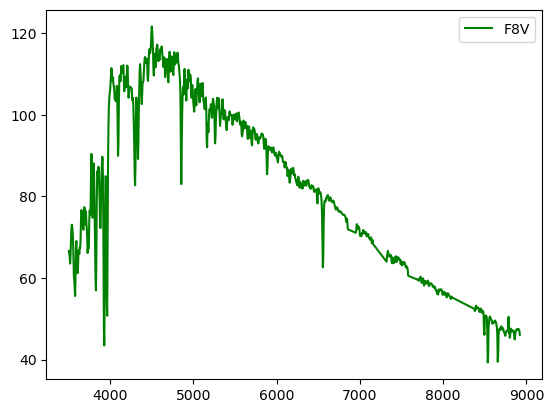

In [209]:
plot(U, V, F8V_star, get_variable_name(U), get_variable_name(V), get_variable_name(F8V_star).split('_')[0])

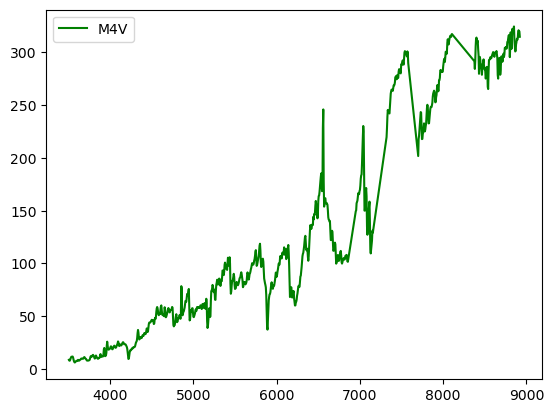

In [210]:
plot(U, V, M4V_star, get_variable_name(U), get_variable_name(V), get_variable_name(M4V_star).split('_')[0])

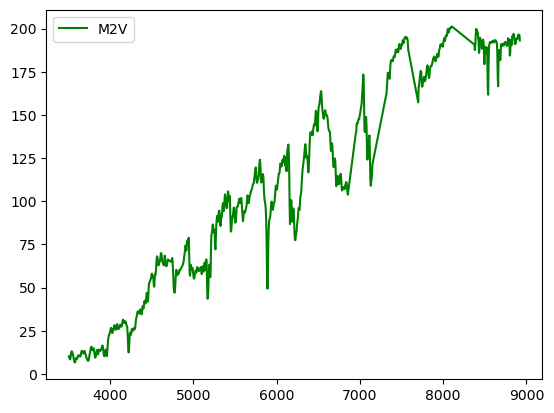

In [211]:
plot(U, V, M2V_star, get_variable_name(U), get_variable_name(V), get_variable_name(M2V_star).split('_')[0])

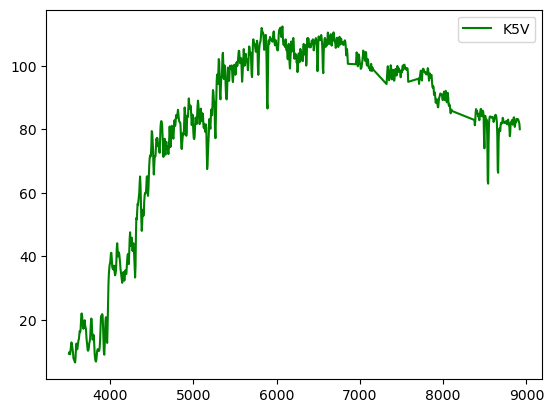

In [212]:
plot(U, V, K5V_star, get_variable_name(U), get_variable_name(V), get_variable_name(K5V_star).split('_')[0])

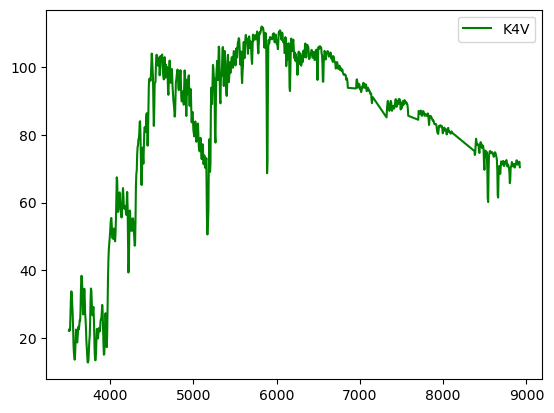

In [213]:
plot(U, V, K4V_star, get_variable_name(U), get_variable_name(V), get_variable_name(K4V_star).split('_')[0])

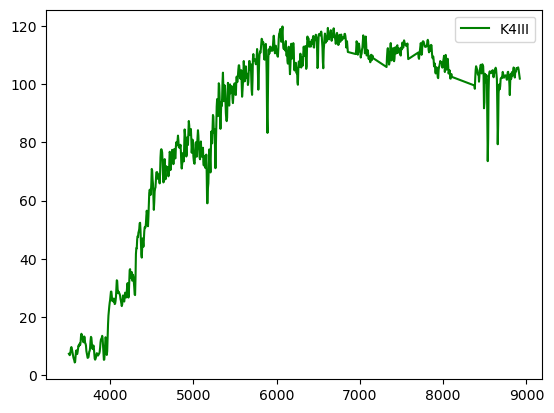

In [214]:
plot(U, V, K4III_star, get_variable_name(U), get_variable_name(V), get_variable_name(K4III_star).split('_')[0])

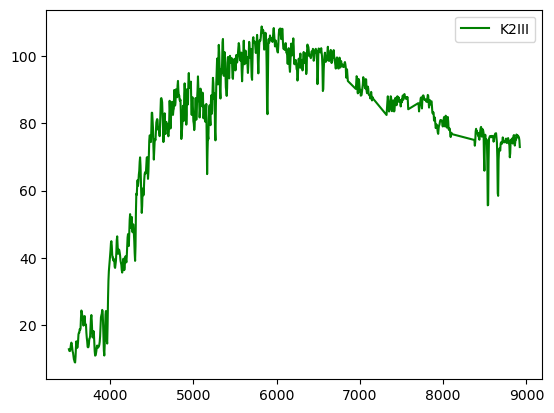

In [215]:
plot(U, V, K2III_star, get_variable_name(U), get_variable_name(V), get_variable_name(K2III_star).split('_')[0])

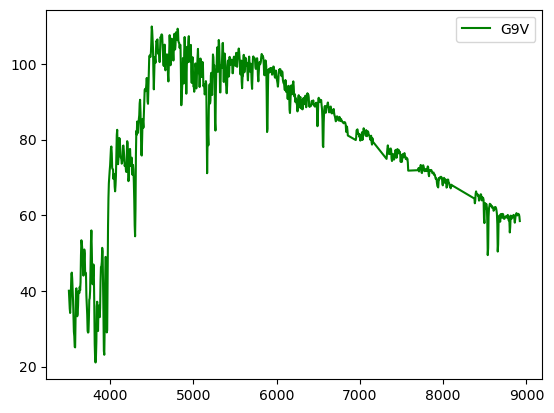

In [216]:
plot(U, V, G9V_star, get_variable_name(U), get_variable_name(V), get_variable_name(G9V_star).split('_')[0])

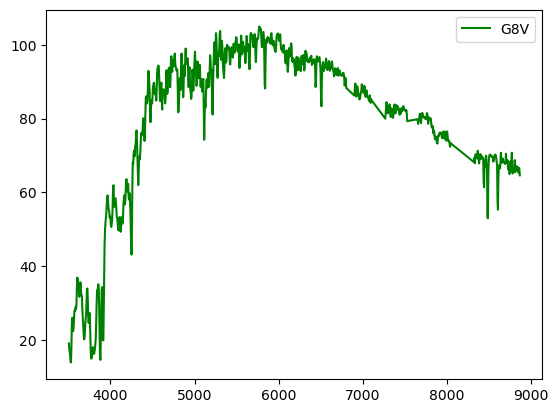

In [217]:
plot(U, V, G8V_star, get_variable_name(U), get_variable_name(V), get_variable_name(G8V_star).split('_')[0])

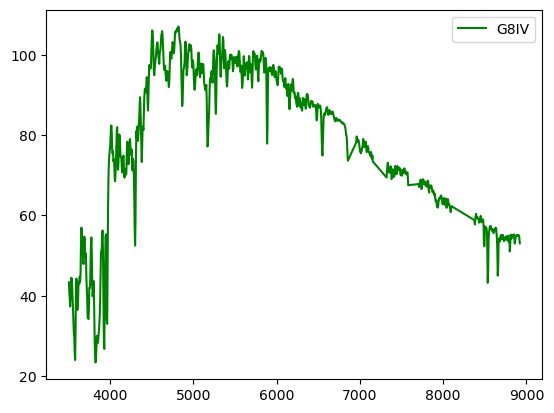

In [218]:
plot(U, V, G8IV_star, get_variable_name(U), get_variable_name(V), get_variable_name(G8IV_star).split('_')[0])

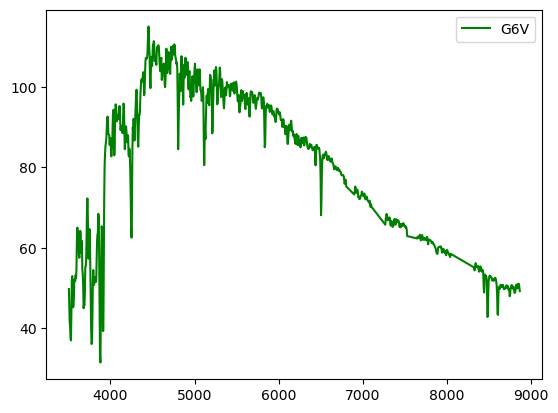

In [219]:
plot(U, V, G6V_star, get_variable_name(U), get_variable_name(V), get_variable_name(G6V_star).split('_')[0]) 

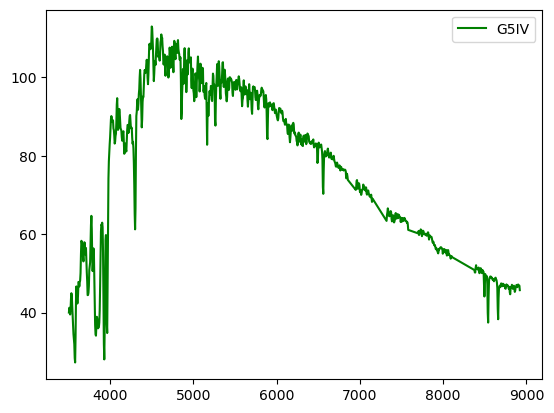

In [220]:
plot(U, V, G5IV_star, get_variable_name(U), get_variable_name(V), get_variable_name(G5IV_star).split('_')[0]) 

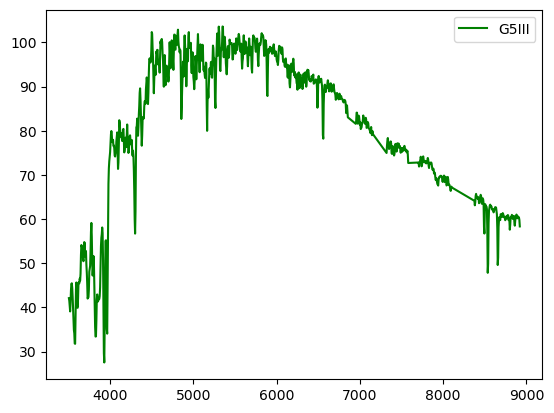

In [221]:
plot(U, V, G5III_star, get_variable_name(U), get_variable_name(V), get_variable_name(G5III_star).split('_')[0])

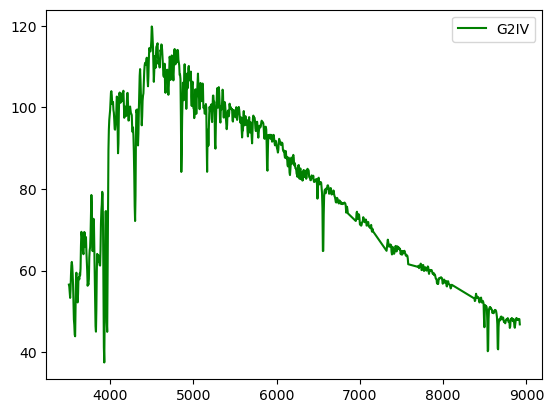

In [222]:
plot(U, V, G2IV_star, get_variable_name(U), get_variable_name(V), get_variable_name(G2IV_star).split('_')[0])

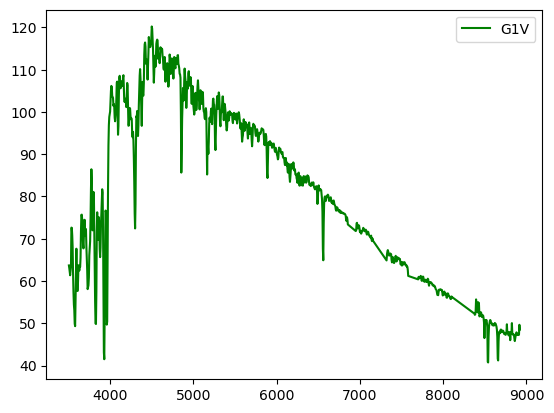

In [223]:
plot(U, V, G1V_star, get_variable_name(U), get_variable_name(V), get_variable_name(G1V_star).split('_')[0])

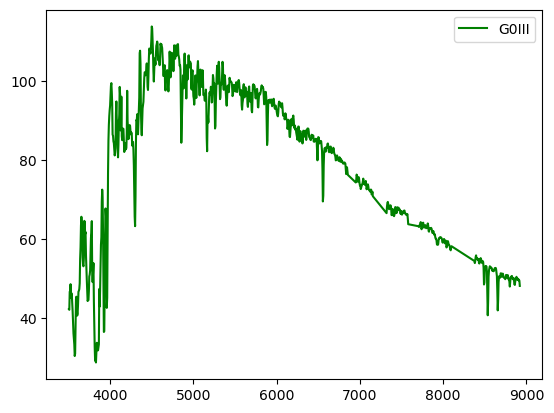

In [224]:
plot(U, V, G0III_star, get_variable_name(U), get_variable_name(V), get_variable_name(G0III_star).split('_')[0])

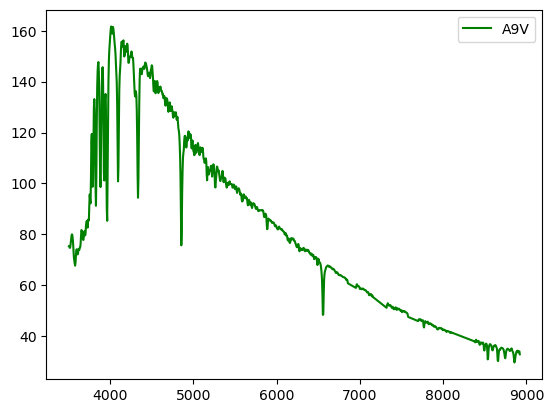

In [225]:
plot(U, V, A9V_star, get_variable_name(U), get_variable_name(V), get_variable_name(A9V_star).split('_')[0])

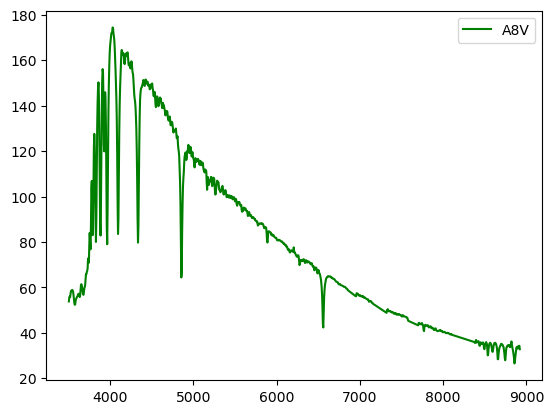

In [226]:
plot(U, V, A8V_star, get_variable_name(U), get_variable_name(V), get_variable_name(A8V_star).split('_')[0])

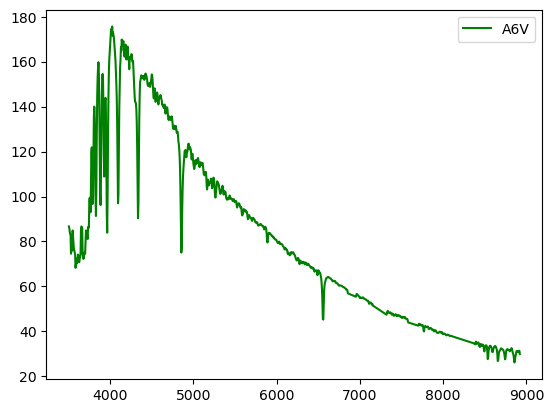

In [227]:
plot(U, V, A6V_star, get_variable_name(U), get_variable_name(V), get_variable_name(A6V_star).split('_')[0])

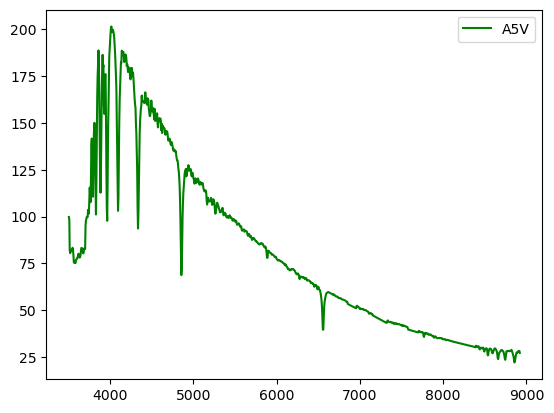

In [228]:
plot(U, V, A5V_star, get_variable_name(U), get_variable_name(V), get_variable_name(A5V_star).split('_')[0])

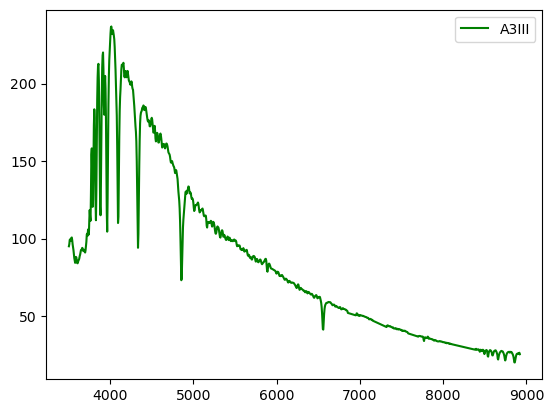

In [229]:
plot(U, V, A3III_star, get_variable_name(U), get_variable_name(V), get_variable_name(A3III_star).split('_')[0])

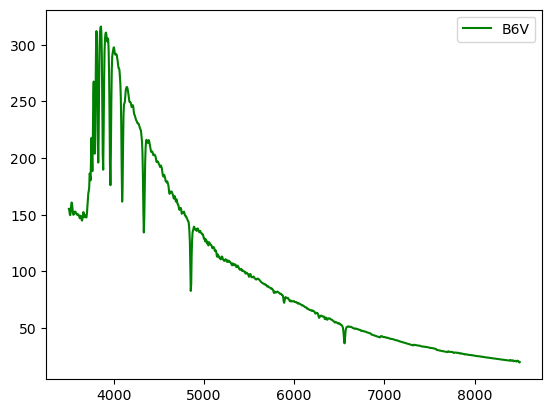

In [230]:
plot(U, V, B6V_star, get_variable_name(U), get_variable_name(V), get_variable_name(B6V_star).split('_')[0])

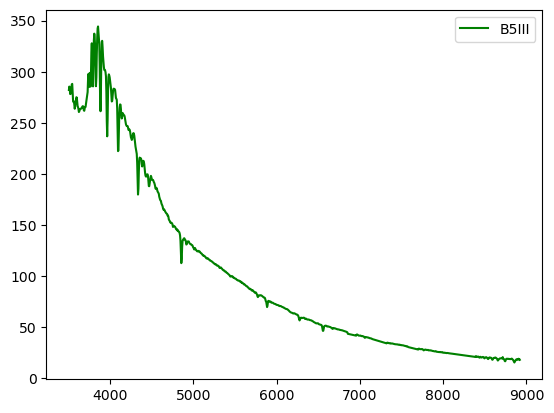

In [231]:
plot(U, V, B5III_star, get_variable_name(U), get_variable_name(V), get_variable_name(B5III_star).split('_')[0])

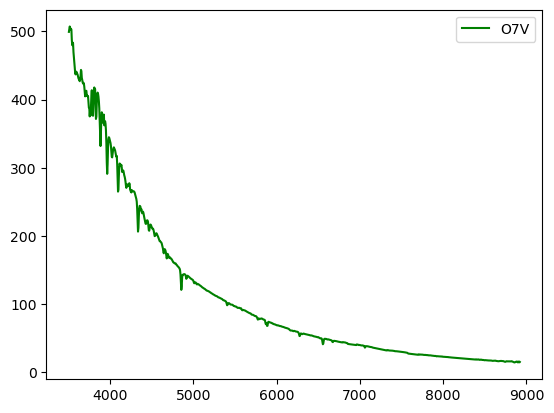

In [232]:
plot(U, V, O7V_star, get_variable_name(U), get_variable_name(V), get_variable_name(O7V_star).split('_')[0])

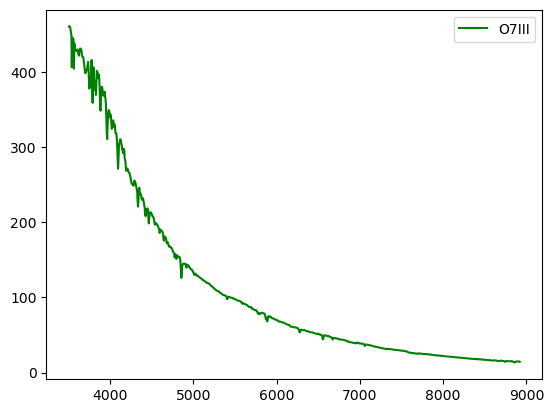

In [233]:
plot(U, V, O7III_star, get_variable_name(U), get_variable_name(V), get_variable_name(O7III_star).split('_')[0])

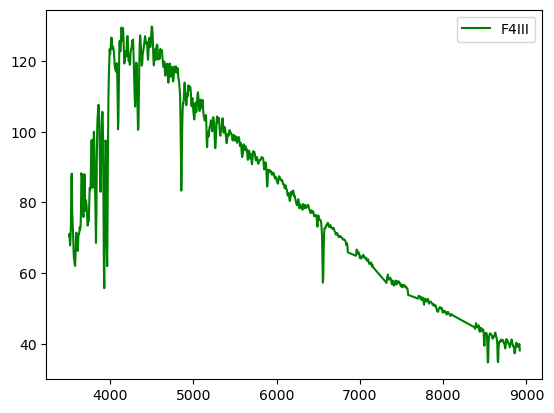

In [234]:
plot(U, V, F4III_star, get_variable_name(U), get_variable_name(V), get_variable_name(F4III_star).split('_')[0])

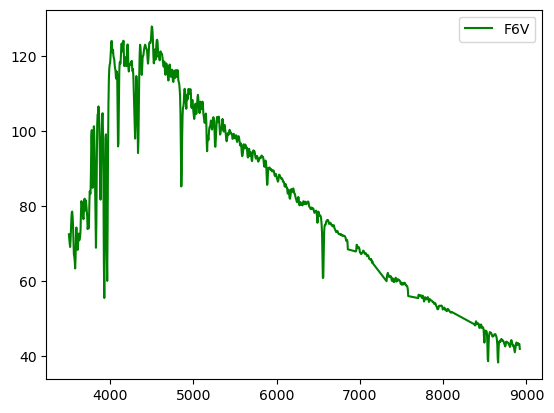

In [235]:
plot(U, V, F6V_star, get_variable_name(U), get_variable_name(V), get_variable_name(F6V_star).split('_')[0])

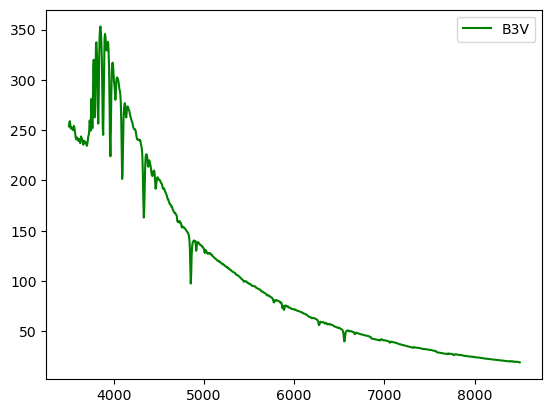

In [236]:
plot(U, V, B3V_star, get_variable_name(U), get_variable_name(V), get_variable_name(B3V_star).split('_')[0])

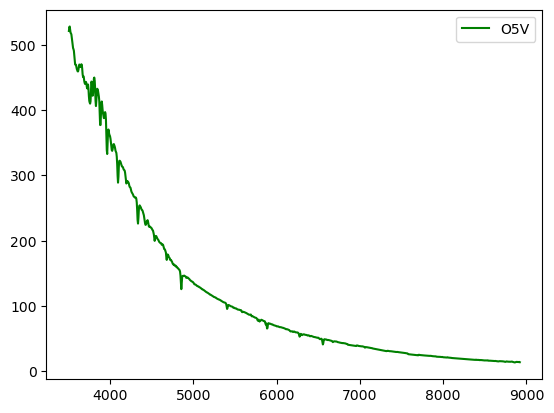

In [237]:
plot(U, V, O5V_star, get_variable_name(U), get_variable_name(V), get_variable_name(O5V_star).split('_')[0])

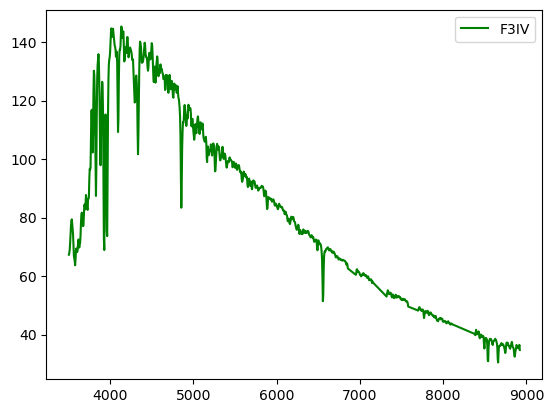

In [238]:
plot(U, V, F3IV_star, get_variable_name(U), get_variable_name(V), get_variable_name(F3IV_star).split('_')[0])

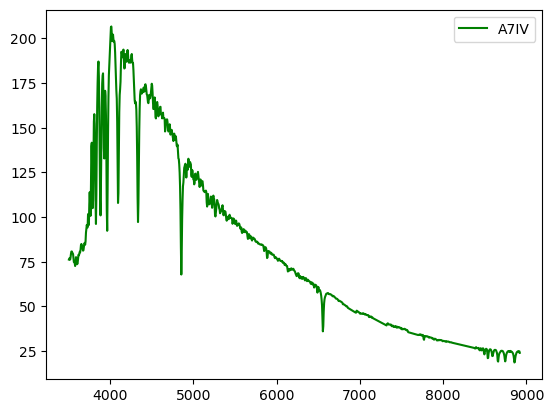

In [239]:
plot(U, V, A7IV_star, get_variable_name(U), get_variable_name(V), get_variable_name(A7IV_star).split('_')[0])

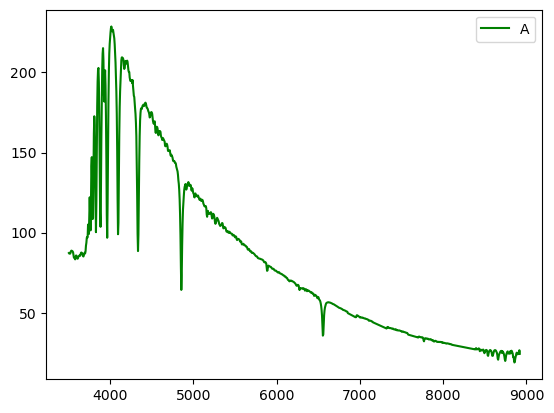

In [240]:
plot(U, V, A_star, get_variable_name(U), get_variable_name(V), get_variable_name(A_star).split('_')[0])

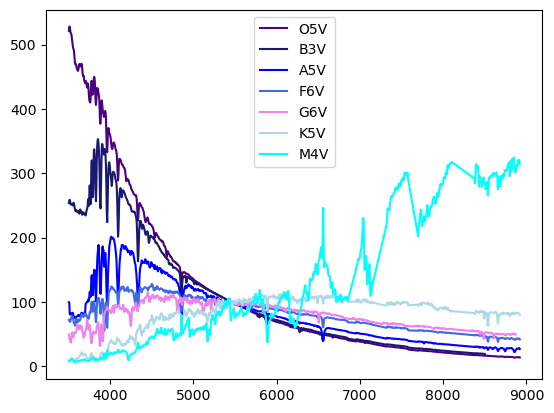

In [356]:
fig1 = plt.figure()
plt.plot(O5V_star[:, 0], O5V_star[:, 1], color='indigo', label='O5V')

plt.plot(B3V_star[:, 0], B3V_star[:, 1], color='midnightblue', label='B3V')


plt.plot(A5V_star[:, 0], A5V_star[:, 1], color='blue', label='A5V')


plt.plot(F6V_star[:, 0], F6V_star[:, 1], color='royalblue', label='F6V')

plt.plot(G6V_star[:, 0], G6V_star[:, 1], color='violet', label='G6V')

plt.plot(K5V_star[:, 0], K5V_star[:, 1], color='lightblue', label='K5V')

plt.plot(M4V_star[:, 0], M4V_star[:, 1], color='aqua', label='M4V')
plt.legend(loc='best')

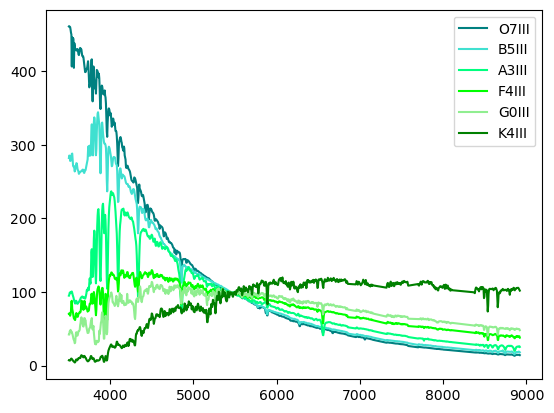

In [376]:
fig1 = plt.figure()
plt.plot(O7III_star[:, 0], O7III_star[:, 1], color='teal', label='O7III')
plt.plot(B5III_star[:, 0], B5III_star[:, 1], color='turquoise', label='B5III')
plt.plot(A3III_star[:, 0], A3III_star[:, 1], color='springgreen', label='A3III')
plt.plot(F4III_star[:, 0], F4III_star[:, 1], color='lime', label='F4III')
plt.plot(G0III_star[:, 0], G0III_star[:, 1], color='lightgreen', label='G0III')
plt.plot(K4III_star[:, 0], K4III_star[:, 1], color='green', label='K4III')
plt.legend(loc='best')

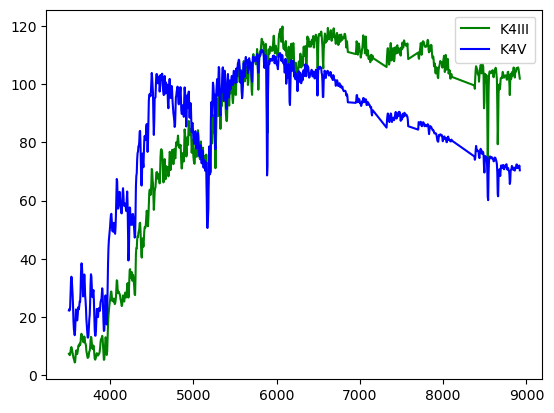

In [13]:
fig1 = plt.figure()
plt.plot(K4III_star[:, 0], K4III_star[:, 1], color='green', label='K4III')
plt.plot(K4V_star[:, 0], K4V_star[:, 1], color='blue', label='K4V')
plt.legend(loc='best')

In [26]:
def planck(wl, c, T):
    return ((c*2*np.pi*6.62*(9e-7)/(((wl)**5)))/(np.exp(3*0.662/(wl*T*1.38))-1))*1e-8

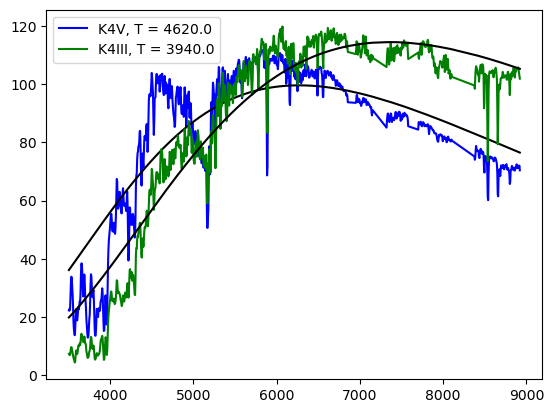

In [34]:
poptK4V, pcovK4V = curve_fit(planck, K4V_star[:, 0]*1e-8, K4V_star[:, 1], p0=[1e5, 6700])
poptK4III, pcovK4III = curve_fit(planck, K4III_star[:, 0]*1e-8, K4III_star[:, 1], p0=[1e5, 6700])
fig1 = plt.figure()
plt.plot(K4V_star[:, 0], K4V_star[:, 1], color='blue', label='K4V, T = %s' % np.round(poptK4V[1], -1))
plt.plot(K4V_star[:, 0], planck(K4V_star[:, 0]*1e-8, *poptK4V), color='black')
plt.plot(K4III_star[:, 0], K4III_star[:, 1], color='green', label='K4III, T = %s' % np.round(poptK4III[1], -1))
plt.plot(K4III_star[:, 0], planck(K4III_star[:, 0]*1e-8, *poptK4III), color='black')
plt.legend(loc='best')

Temperature bb 6607.698260878601


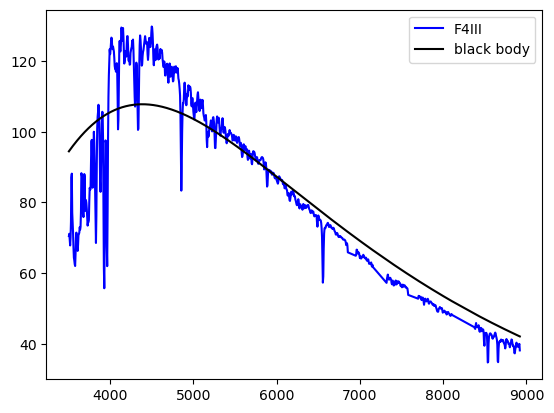

In [322]:
popt, pcov = curve_fit(planck, F4III_star[:, 0]*1e-8, F4III_star[:, 1], p0=[1e5, 6700])
plt.plot(F4III_star[:, 0], F4III_star[:, 1], color='blue', label='F4III')
plt.plot(F4III_star[:, 0], planck(F4III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 89654.70852884882


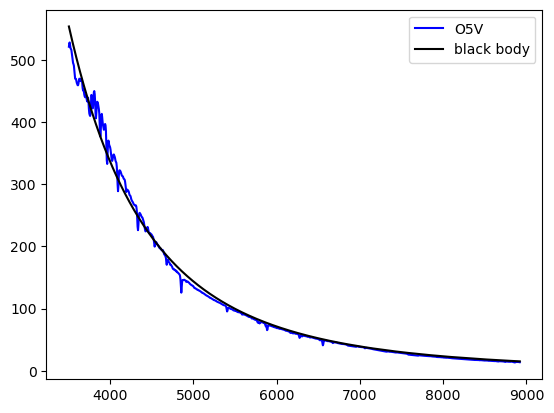

In [323]:
popt, pcov = curve_fit(planck, O5V_star[:, 0]*1e-8, O5V_star[:, 1], p0=[1e5, 6700])
plt.plot(O5V_star[:, 0], O5V_star[:, 1], color='blue', label='O5V')
plt.plot(O5V_star[:, 0], planck(O5V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 44290.265855056234


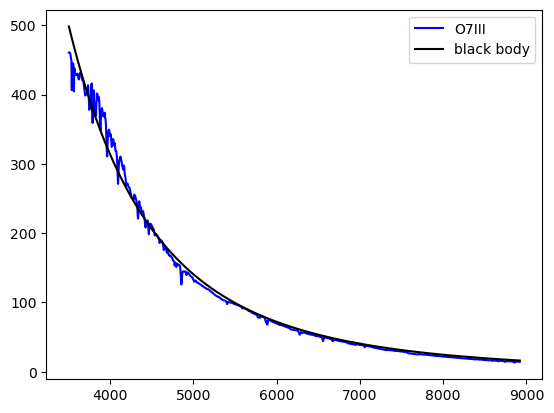

In [324]:
popt, pcov = curve_fit(planck, O7III_star[:, 0]*1e-8, O7III_star[:, 1], p0=[1e5, 6700])
plt.plot(O7III_star[:, 0], O7III_star[:, 1], color='blue', label='O7III')
plt.plot(O7III_star[:, 0], planck(O7III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 54853.91284408308


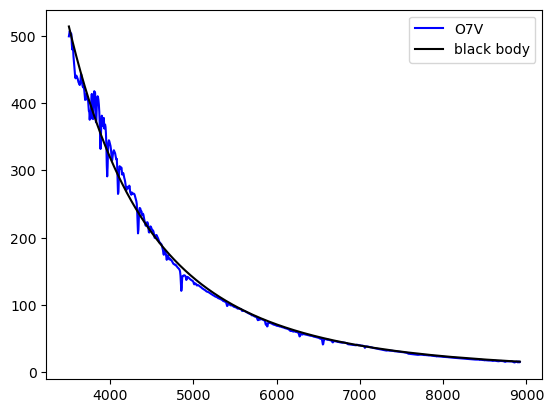

In [325]:
popt, pcov = curve_fit(planck, O7V_star[:, 0]*1e-8, O7V_star[:, 1], p0=[1e5, 6700])
plt.plot(O7V_star[:, 0], O7V_star[:, 1], color='blue', label='O7V')
plt.plot(O7V_star[:, 0], planck(O7V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 15043.88627309268


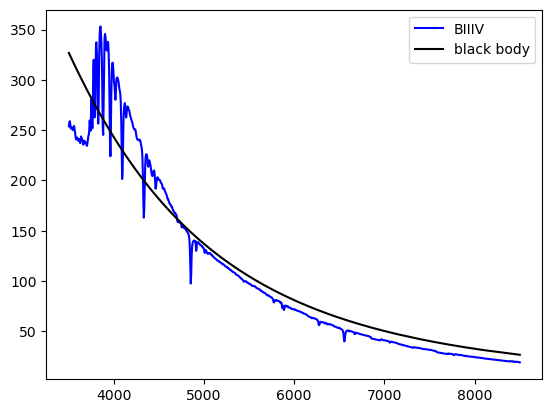

In [326]:
popt, pcov = curve_fit(planck, B3V_star[:, 0]*1e-8, B3V_star[:, 1], p0=[1e5, 6700])
plt.plot(B3V_star[:, 0], B3V_star[:, 1], color='blue', label='BIIIV')
plt.plot(B3V_star[:, 0], planck(B3V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 16521.015909707337


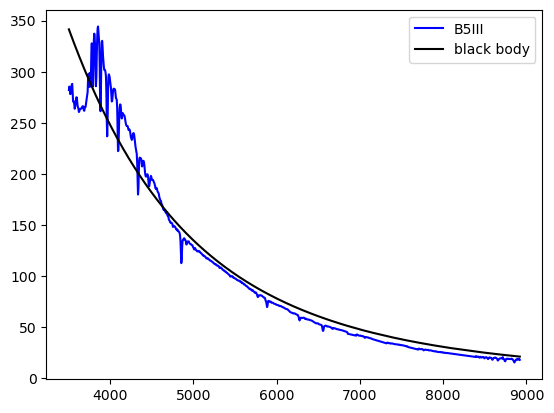

In [327]:
popt, pcov = curve_fit(planck, B5III_star[:, 0]*1e-8, B5III_star[:, 1], p0=[1e5, 6700])
plt.plot(B5III_star[:, 0], B5III_star[:, 1], color='blue', label='B5III')
plt.plot(B5III_star[:, 0], planck(B5III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 11446.545511602193


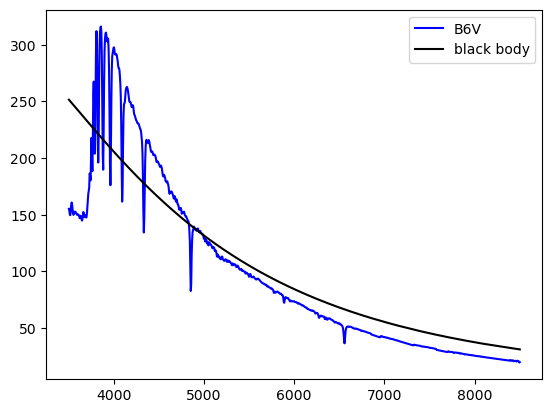

In [328]:
popt, pcov = curve_fit(planck, B6V_star[:, 0]*1e-8, B6V_star[:, 1], p0=[1e5, 6700])
plt.plot(B6V_star[:, 0], B6V_star[:, 1], color='blue', label='B6V')
plt.plot(B6V_star[:, 0], planck(B6V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 8676.268309979858


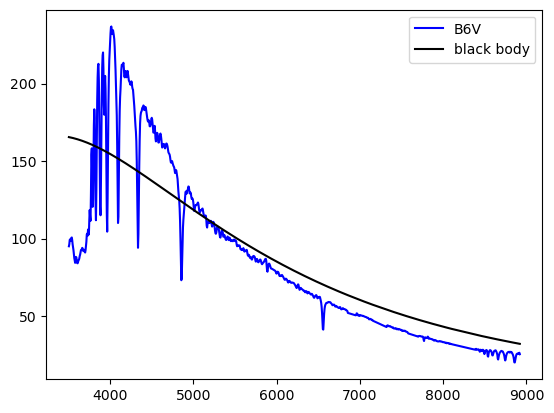

In [329]:
popt, pcov = curve_fit(planck, A3III_star[:, 0]*1e-8, A3III_star[:, 1], p0=[1e5, 6700])
plt.plot(A3III_star[:, 0], A3III_star[:, 1], color='blue', label='B6V')
plt.plot(A3III_star[:, 0], planck(A3III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 8178.118584927161


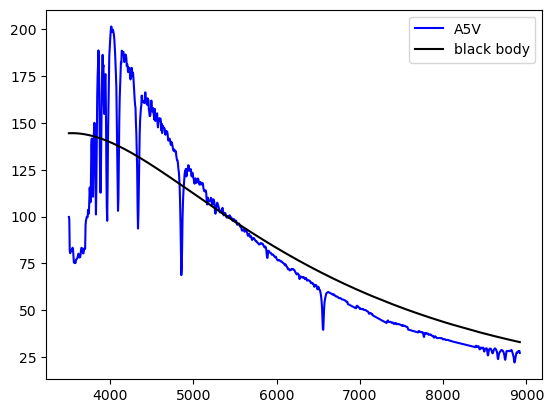

In [330]:
popt, pcov = curve_fit(planck, A5V_star[:, 0]*1e-8, A5V_star[:, 1], p0=[1e5, 6700])
plt.plot(A5V_star[:, 0], A5V_star[:, 1], color='blue', label='A5V')
plt.plot(A5V_star[:, 0], planck(A5V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 7615.901521144419


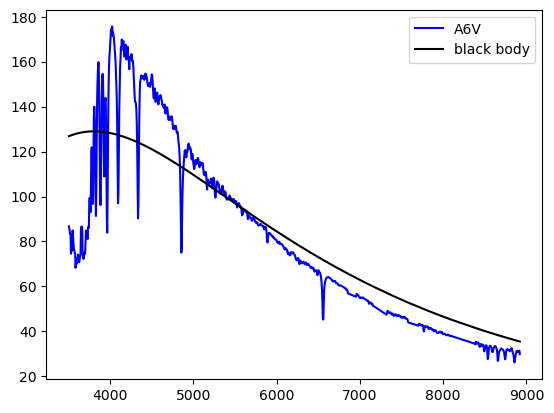

In [331]:
popt, pcov = curve_fit(planck, A6V_star[:, 0]*1e-8, A6V_star[:, 1], p0=[1e5, 6700])
plt.plot(A6V_star[:, 0], A6V_star[:, 1], color='blue', label='A6V')
plt.plot(A6V_star[:, 0], planck(A6V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 8319.825540255071


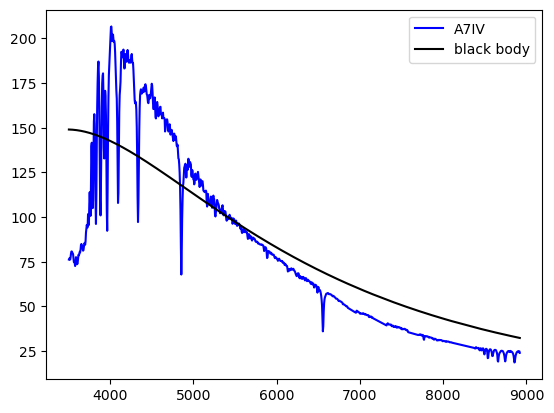

In [332]:
popt, pcov = curve_fit(planck, A7IV_star[:, 0]*1e-8, A7IV_star[:, 1], p0=[1e5, 6700])
plt.plot(A7IV_star[:, 0], A7IV_star[:, 1], color='blue', label='A7IV')
plt.plot(A7IV_star[:, 0], planck(A7IV_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 7264.009172819842


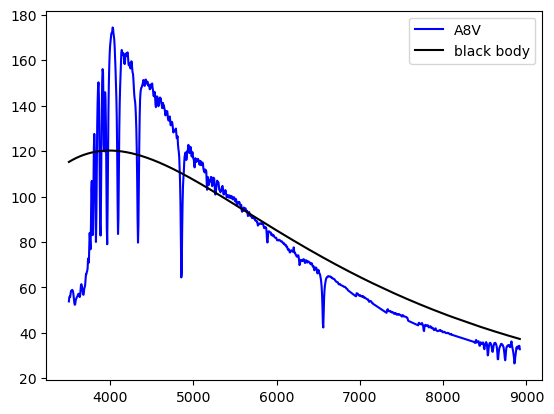

In [333]:
popt, pcov = curve_fit(planck, A8V_star[:, 0]*1e-8, A8V_star[:, 1], p0=[1e5, 6700])
plt.plot(A8V_star[:, 0], A8V_star[:, 1], color='blue', label='A8V')
plt.plot(A8V_star[:, 0], planck(A8V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 7331.658500904362


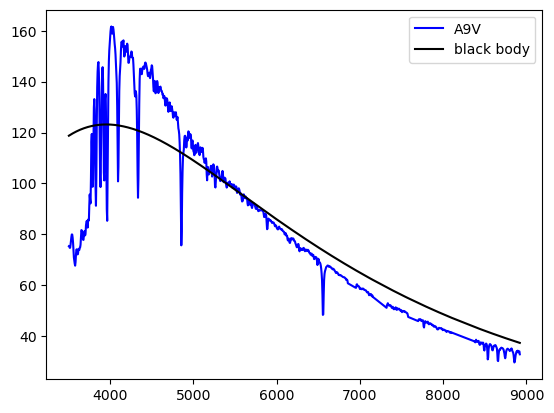

In [334]:
popt, pcov = curve_fit(planck, A9V_star[:, 0]*1e-8, A9V_star[:, 1], p0=[1e5, 6700])
plt.plot(A9V_star[:, 0], A9V_star[:, 1], color='blue', label='A9V')
plt.plot(A9V_star[:, 0], planck(A9V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 7065.475334280845


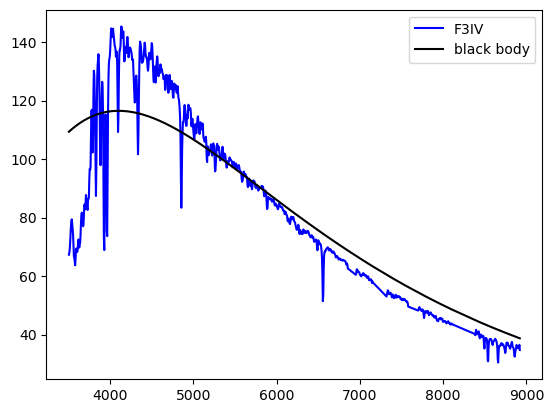

In [335]:
popt, pcov = curve_fit(planck, F3IV_star[:, 0]*1e-8, F3IV_star[:, 1], p0=[1e5, 6700])
plt.plot(F3IV_star[:, 0], F3IV_star[:, 1], color='blue', label='F3IV')
plt.plot(F3IV_star[:, 0], planck(F3IV_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 6464.2292066005475


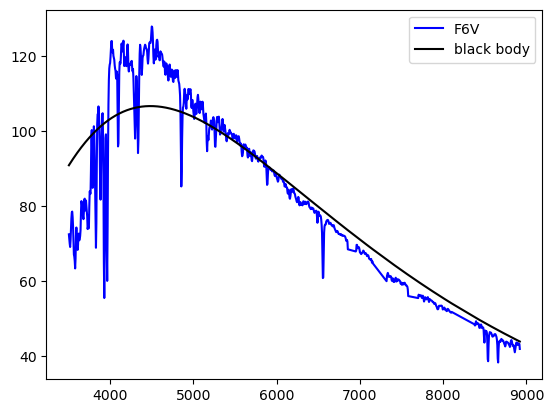

In [336]:
popt, pcov = curve_fit(planck, F6V_star[:, 0]*1e-8, F6V_star[:, 1], p0=[1e5, 6700])
plt.plot(F6V_star[:, 0], F6V_star[:, 1], color='blue', label='F6V')
plt.plot(F6V_star[:, 0], planck(F6V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 6104.53756788693


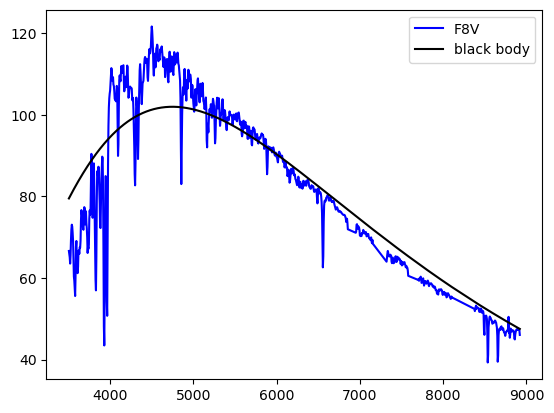

In [337]:
popt, pcov = curve_fit(planck, F8V_star[:, 0]*1e-8, F8V_star[:, 1], p0=[1e5, 6700])
plt.plot(F8V_star[:, 0], F8V_star[:, 1], color='blue', label='F8V')
plt.plot(F8V_star[:, 0], planck(F8V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5554.528985330441


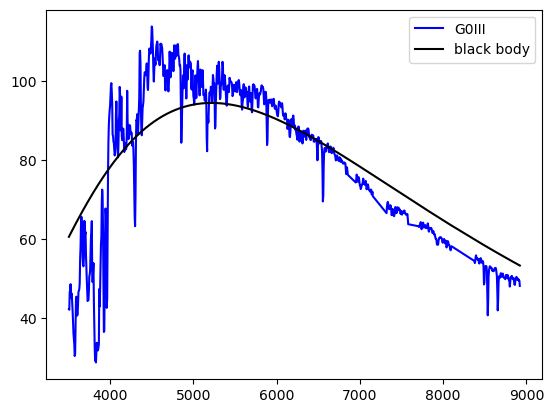

In [338]:
popt, pcov = curve_fit(planck, G0III_star[:, 0]*1e-8, G0III_star[:, 1], p0=[1e5, 6700])
plt.plot(G0III_star[:, 0], G0III_star[:, 1], color='blue', label='G0III')
plt.plot(G0III_star[:, 0], planck(G0III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5973.251208100976


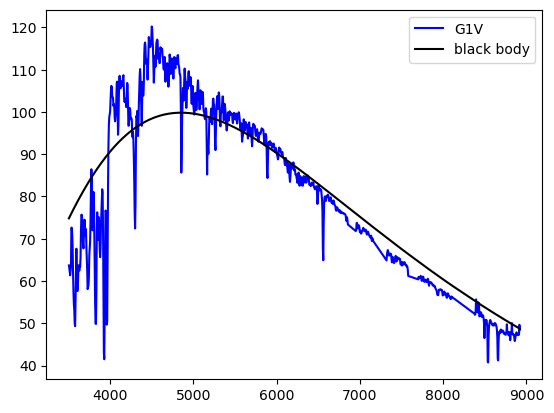

In [339]:
popt, pcov = curve_fit(planck, G1V_star[:, 0]*1e-8, G1V_star[:, 1], p0=[1e5, 6700])
plt.plot(G1V_star[:, 0], G1V_star[:, 1], color='blue', label='G1V')
plt.plot(G1V_star[:, 0], planck(G1V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5875.034487310982


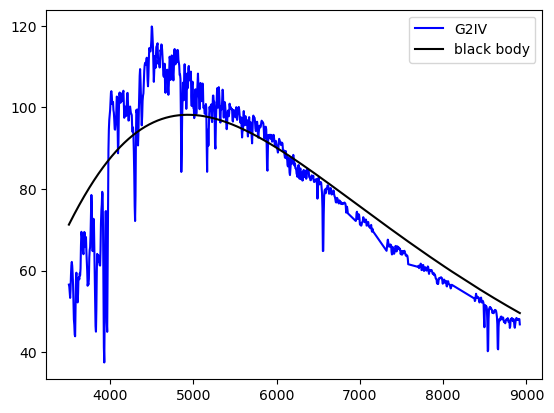

In [340]:
popt, pcov = curve_fit(planck, G2IV_star[:, 0]*1e-8, G2IV_star[:, 1], p0=[1e5, 6700])
plt.plot(G2IV_star[:, 0], G2IV_star[:, 1], color='blue', label='G2IV')
plt.plot(G2IV_star[:, 0], planck(G2IV_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5172.709015451502


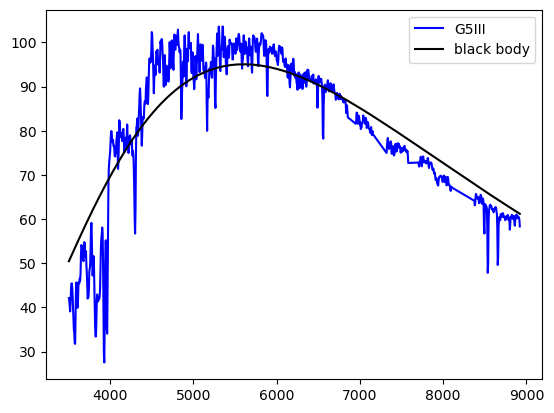

In [341]:
popt, pcov = curve_fit(planck, G5III_star[:, 0]*1e-8, G5III_star[:, 1], p0=[1e5, 6700])
plt.plot(G5III_star[:, 0], G5III_star[:, 1], color='blue', label='G5III')
plt.plot(G5III_star[:, 0], planck(G5III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5612.7618424769225


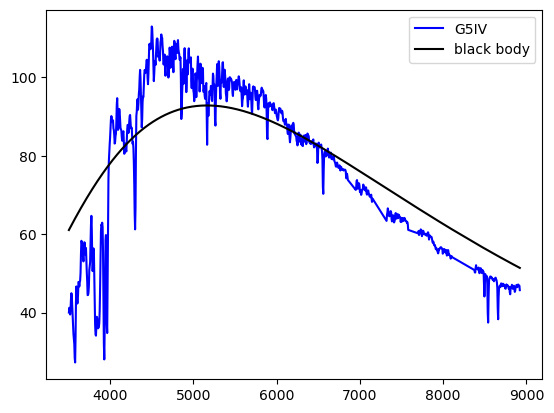

In [342]:
popt, pcov = curve_fit(planck, G5IV_star[:, 0]*1e-8, G5IV_star[:, 1], p0=[1e5, 6700])
plt.plot(G5IV_star[:, 0], G5IV_star[:, 1], color='blue', label='G5IV')
plt.plot(G5IV_star[:, 0], planck(G5IV_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5692.50498432964


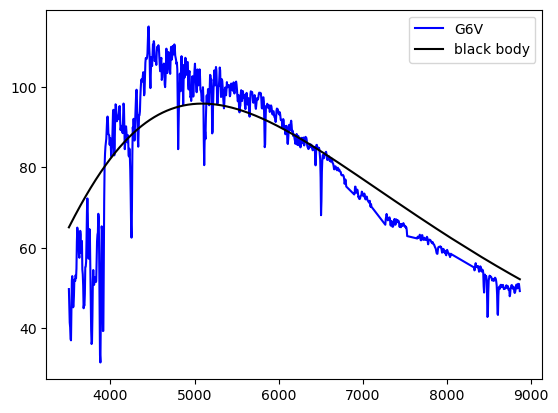

In [343]:
popt, pcov = curve_fit(planck, G6V_star[:, 0]*1e-8, G6V_star[:, 1], p0=[1e5, 6700])
plt.plot(G6V_star[:, 0], G6V_star[:, 1], color='blue', label='G6V')
plt.plot(G6V_star[:, 0], planck(G6V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5261.3767595314785


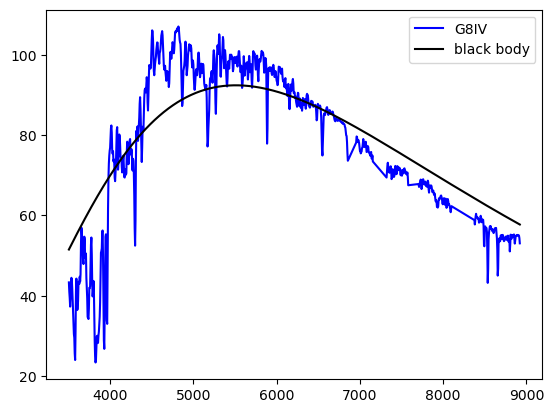

In [344]:
popt, pcov = curve_fit(planck, G8IV_star[:, 0]*1e-8, G8IV_star[:, 1], p0=[1e5, 6700])
plt.plot(G8IV_star[:, 0], G8IV_star[:, 1], color='blue', label='G8IV')
plt.plot(G8IV_star[:, 0], planck(G8IV_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 4771.916292542177


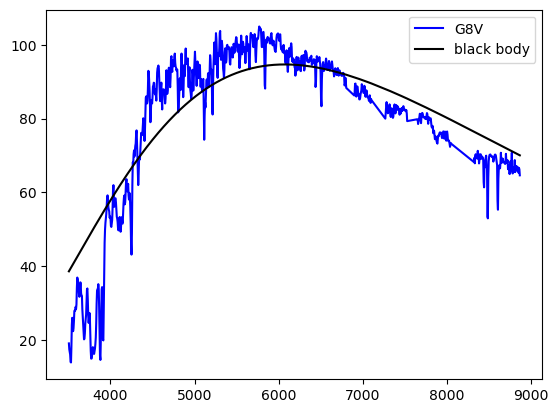

In [345]:
popt, pcov = curve_fit(planck, G8V_star[:, 0]*1e-8, G8V_star[:, 1], p0=[1e5, 6700])
plt.plot(G8V_star[:, 0], G8V_star[:, 1], color='blue', label='G8V')
plt.plot(G8V_star[:, 0], planck(G8V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 5157.135485578597


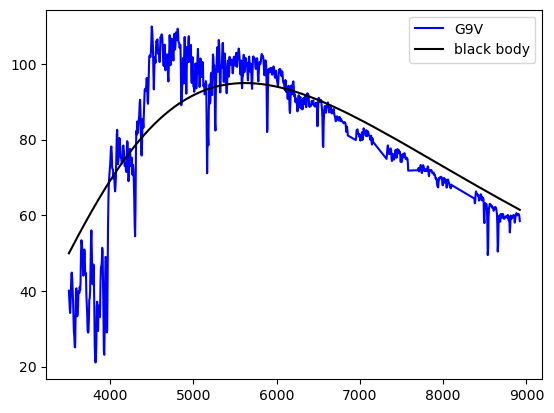

In [346]:
popt, pcov = curve_fit(planck, G9V_star[:, 0]*1e-8, G9V_star[:, 1], p0=[1e5, 6700])
plt.plot(G9V_star[:, 0], G9V_star[:, 1], color='blue', label='G9V')
plt.plot(G9V_star[:, 0], planck(G9V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 4442.07812092945


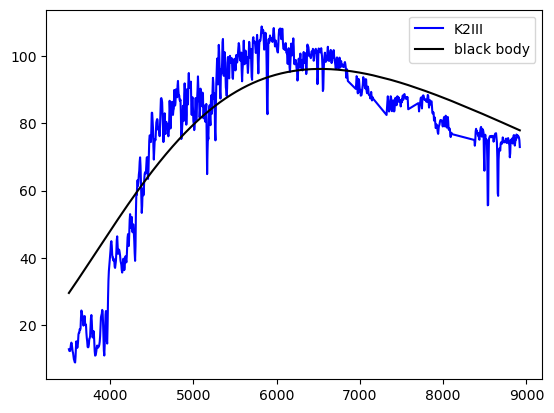

In [347]:
popt, pcov = curve_fit(planck, K2III_star[:, 0]*1e-8, K2III_star[:, 1], p0=[1e5, 6700])
plt.plot(K2III_star[:, 0], K2III_star[:, 1], color='blue', label='K2III')
plt.plot(K2III_star[:, 0], planck(K2III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 3940.8845804722823


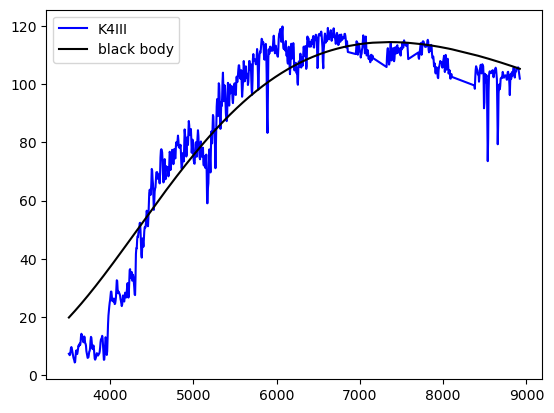

In [348]:
popt, pcov = curve_fit(planck, K4III_star[:, 0]*1e-8, K4III_star[:, 1], p0=[1e5, 6700])
plt.plot(K4III_star[:, 0], K4III_star[:, 1], color='blue', label='K4III')
plt.plot(K4III_star[:, 0], planck(K4III_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 4624.191399076401


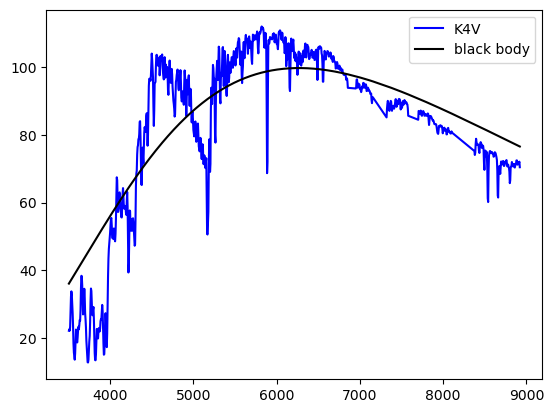

In [349]:
popt, pcov = curve_fit(planck, K4V_star[:, 0]*1e-8, K4V_star[:, 1], p0=[1e5, 6700])
plt.plot(K4V_star[:, 0], K4V_star[:, 1], color='blue', label='K4V')
plt.plot(K4V_star[:, 0], planck(K4V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 4245.171606661747


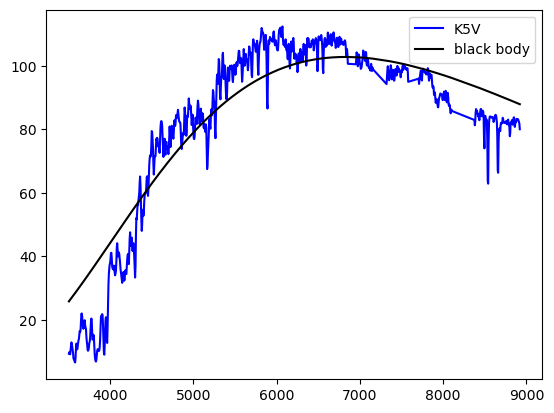

In [350]:
popt, pcov = curve_fit(planck, K5V_star[:, 0]*1e-8, K5V_star[:, 1], p0=[1e5, 6700])
plt.plot(K5V_star[:, 0], K5V_star[:, 1], color='blue', label='K5V')
plt.plot(K5V_star[:, 0], planck(K5V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 3158.184246032626


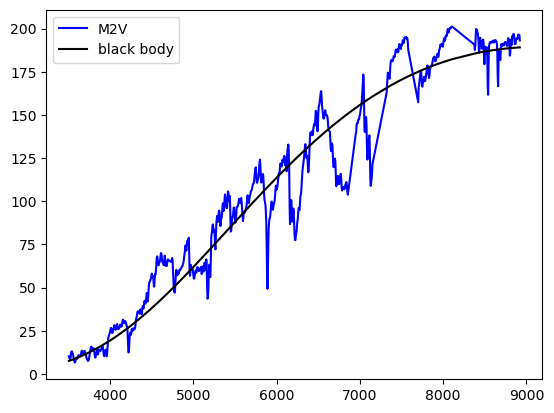

In [351]:
popt, pcov = curve_fit(planck, M2V_star[:, 0]*1e-8, M2V_star[:, 1], p0=[1e5, 6700])
plt.plot(M2V_star[:, 0], M2V_star[:, 1], color='blue', label='M2V')
plt.plot(M2V_star[:, 0], planck(M2V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])

Temperature bb 2552.806813554081


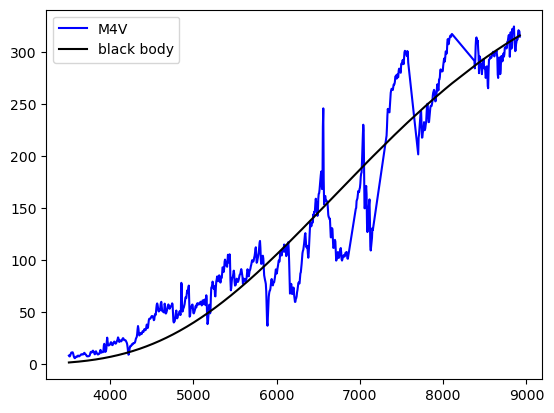

In [352]:
popt, pcov = curve_fit(planck, M4V_star[:, 0]*1e-8, M4V_star[:, 1], p0=[1e5, 6700])
plt.plot(M4V_star[:, 0], M4V_star[:, 1], color='blue', label='M4V')
plt.plot(M4V_star[:, 0], planck(M4V_star[:, 0]*1e-8, *popt), color='black', label='black body')
plt.legend(loc='best')
print('Temperature bb', popt[1])